<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 8</center>

***

<center>Basic Predictive Modelling</center>

<center>Logistic Regression + Decision Trees</center>

***

<center>2 November 2026<center>
<center>Rahman Peimankar<center>

## Where we are in the course

Lecture 4:

**raw signal → quality → filtering → segmentation**

Lecture 5:

**signals → interpretable physiological features**

Lecture 7:

**time-series windows → automated features → feature table**

Today:

**feature table → predictive model → probability / class prediction**


## Learning outcomes

By the end of today you should be able to:

1. identify `X` features and `y` target labels;
2. create simple training and test data;
3. explain the basic idea of Logistic Regression;
4. interpret predicted probabilities and a classification threshold;
5. explain the basic structure of a Decision Tree;
6. explain Gini impurity at an intuitive level;
7. train both models using scikit-learn;
8. inspect Logistic Regression coefficients and tree feature importances;
9. recognize basic strengths and limitations of the two models.

## From a feature table to machine learning

After Lectures 5 and 7, our data may look like:

| window_id | std | range | derivative RMS | ... | label |
|---|---:|---:|---:|---:|---:|
| 118_clean_00 | ... | ... | ... | ... | 0 |
| 118_noisy_00 | ... | ... | ... | ... | 1 |

For supervised learning:

```text
X = input features

y = known target label
```

The model learns a relationship:

```text
features → target
```

## Classification vs regression

### Regression

Predict a continuous number:

```text
age
blood pressure
future glucose
```

### Classification

Predict a category:

```text
normal / abnormal
AF / non-AF
low-quality / high-quality
```

Today we focus on **binary classification**.

## Our running example

We will use real ECG windows from:

- MIT-BIH records `118` and `119`;
- their noisy NSTDB counterparts `118e12` and `119e12`;
- 10-second windows;
- simple signal features.

Target:

```text
0 = clean ECG
1 = noisy ECG
```

The purpose is to understand the modelling workflow — not to build a clinical classifier.

## Important evaluation note

Today we use a simple train/test split to learn the **model API**.

Some windows come from the same original recording.

So this is **not yet a rigorous evaluation design**.

In Lecture 9 we will replace this with:

- patient/record-wise grouping;
- leakage-safe splits;
- better metrics;
- bias/fairness analysis.

## Setup

We will use:

- NumPy and pandas;
- WFDB for ECG data;
- scikit-learn for models;
- Matplotlib for plots.

In [1]:
# Run once if needed:
# %pip install wfdb numpy pandas matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, plot_tree)
from sklearn.metrics import (accuracy_score, ConfusionMatrixDisplay)

plt.rcParams["figure.figsize"] = (12, 4)

## Build a small real ECG feature table

We reuse skills from earlier lectures, but keep the features deliberately simple:

- standard deviation;
- peak-to-peak range;
- mean absolute change;
- derivative RMS;
- mean absolute amplitude.

Each **10-second window becomes one row**.

In [3]:
def window_features(x, fs, record_id, label, window_s=10):

    n = int(window_s * fs)
    rows = []

    for start in range(0, len(x) - n + 1, n):

        w = x[start:start + n]
        dx = np.diff(w)

        rows.append({
            "record_id": record_id,
            "start_s": start / fs,
            "std": np.std(w),
            "amplitude_range": np.ptp(w),
            "mean_abs_change": np.mean(np.abs(dx)),
            "derivative_rms": np.sqrt(np.mean(dx**2)),
            "mean_abs_amplitude": np.mean(np.abs(w)),
            "label":label})

    return rows

## Load clean and noisy ECG records

We use two underlying ECG records so our example is larger than a single-record toy problem.

In [4]:
start_s = 305
duration_s = 120

pairs = [("118", "118e12"), ("119", "119e12")]
rows = []

for clean_name, noisy_name in pairs:

    header = wfdb.rdheader(clean_name, pn_dir="mitdb")
    fs = header.fs
    sampfrom = int(start_s * fs)
    sampto = int((start_s + duration_s) * fs)
    
    clean = wfdb.rdrecord(clean_name, pn_dir="mitdb", sampfrom=sampfrom, sampto=sampto, channels=[0])
    noisy = wfdb.rdrecord(noisy_name, pn_dir="nstdb", sampfrom=sampfrom, sampto=sampto, channels=[0])

    rows += window_features(clean.p_signal[:, 0], fs, record_id=clean_name, label=0)
    rows += window_features(noisy.p_signal[:, 0], fs, record_id=noisy_name, label=1)

feature_table = pd.DataFrame(rows)

feature_table.head()

,record_id,start_s,std,amplitude_range,mean_abs_change,derivative_rms,mean_abs_amplitude,label
0,118,0.0,0.420122,3.155,0.031539,0.074601,0.956889,0
1,118,10.0,0.411523,3.020,0.029311,0.071328,0.900621,0
2,118,20.0,0.396817,3.105,0.028540,0.067234,0.969501,0
3,118,30.0,0.319831,2.670,0.025849,0.057450,0.872736,0
4,118,40.0,0.385231,3.155,0.032306,0.067931,0.987139,0


## Define `X` and `y`

The model should not receive:

- record identifiers;
- window start times;
- target labels.

Only the selected numeric features become `X`.

In [5]:
feature_names = ["std", "amplitude_range", "mean_abs_change", "derivative_rms", "mean_abs_amplitude"]

X = feature_table[feature_names]
y = feature_table["label"]

print("X shape:", X.shape)
print()
print("Target counts:")
print(y.value_counts())

X shape: (48, 5)

Target counts:
label
0    24
1    24
Name: count, dtype: int64


## Training data and test data

We need some examples to **fit** the model and separate examples to **check predictions**.

For today:

```text
80% → training
20% → test
```

We also use:

```python
stratify=y
```

so both sets retain approximately the same class balance.

A more rigorous grouped strategy comes in Lecture 9.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training:", X_train.shape)
print("Test:", X_test.shape)

Training: (38, 5)
Test: (10, 5)


# Logistic Regression

A **linear model for classification**.

Despite the word “regression”, scikit-learn uses Logistic Regression as a classifier.

## Logistic Regression intuition


<div>
<table><tr>
<td><img src="img/logistic_curve.JPG" width="390"/></td>
<td>

- Linear regression predicts a continuous value.
- Logistic Regression predicts the probability of a class.
- Instead of an unlimited straight-line output, it uses an **S-shaped logistic function**.
- The resulting probability stays between **0 and 1**.

</td>
</tr></table>

## Linear score → probability

Logistic Regression first calculates a weighted score:

$z = w_1x_1 + w_2x_2 + \cdots + w_px_p + b$

Then the logistic function maps that score to a probability:

$P(y=1 \mid x) = \frac{1}{1 + e^{-z}}$

So the model output can be interpreted as:

```text
estimated probability of class 1
```

## Probability → class


<div>
<center>
<table><tr>
<td><img src="img/logistic_threshold_1.JPG" width="310"/></td>
<td><img src="img/logistic_threshold_2.JPG" width="310"/></td>
<td><img src="img/logistic_threshold_3.JPG" width="310"/></td>
</tr></table>
</div>

A common default rule is:

```text
probability ≥ 0.50 → class 1
probability < 0.50 → class 0
```

The probability and the final class are **not the same thing**.

## How are the coefficients learned?

Logistic Regression is not fitted using the same least-squares idea as ordinary linear regression.

So, how the Logistic Regression algorithm finds teh best fitted curve? 

Here, we introduce the idea of **maximum likelihood**. You shift the line/curve and calculate a new likelihood of the data.

<div>
<center>
<table><tr>
<td><font size='8'><img src="img/Qimage-8.JPG" width="500"/></td>
<td><font size='8'><img src="img/Qimage-9.JPG" width="500"/></td>
<td><font size='8'><img src="img/Qimage-10.JPG" width="500"/></td>
</tr></table>
    
Finally, the curve with the maximum likelihood is selected 

## Why scale features for Logistic Regression?

Our features have different numerical ranges.

For example:

```text
standard deviation      ≈ small values
amplitude range         ≈ larger values
```

Scaling makes their numerical scales more comparable.

We use a scikit-learn `Pipeline`:

```text
StandardScaler
      ↓
LogisticRegression
```

The scaler is fitted using the training data inside the pipeline.

## Fit Logistic Regression

The scikit-learn workflow is intentionally simple:

```text
create model → fit → predict
```

In [7]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000))
])

logistic_model.fit(X_train, y_train)

C:\Users\abpe\AppData\Local\anaconda3\envs\rise\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with 

## `predict()` vs `predict_proba()`

These answer different questions.

### `predict()`

```text
Which class?
```

### `predict_proba()`

```text
What probability did the model assign to each class?
```

For health applications, preserving the probability is often useful.

In [8]:
logistic_predictions = (logistic_model.predict(X_test))
logistic_probabilities = (logistic_model.predict_proba(X_test)[:, 1])

prediction_table = pd.DataFrame({
    "true_label": y_test.to_numpy(),
    "predicted_label": logistic_predictions,
    "probability_class_1": logistic_probabilities
})

prediction_table.head(10)

,true_label,predicted_label,probability_class_1
0,1,1,0.992567
1,0,0,0.078265
2,1,1,0.951162
3,0,0,0.136530
4,0,0,0.095516
5,1,1,0.872903
6,1,1,0.948769
7,1,1,0.938416
8,0,0,0.015596
9,0,0,0.383098


## A first simple result

Today we use accuracy only as a quick sanity check.

Do **not** interpret this as a complete model evaluation.

Lecture 9 will introduce better evaluation design and clinically meaningful metrics.

Logistic Regression accuracy: 1.0


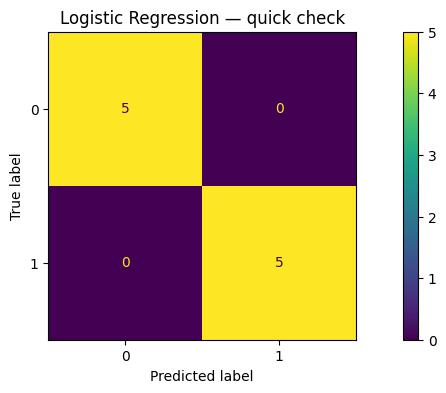

In [9]:
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
print("Logistic Regression accuracy:", round(logistic_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(y_test, logistic_predictions)
plt.title("Logistic Regression — quick check")
plt.show()

## Logistic Regression coefficients

After standardization, each coefficient describes the direction of association between a feature and class 1.

Conceptually:

```text
positive coefficient
    → larger feature values push toward class 1

negative coefficient
    → larger feature values push toward class 0
```

This is **model interpretation**, not proof of causality.

In [10]:
coefficients = (logistic_model .named_steps["model"] .coef_[0])

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "abs_coefficient": np.abs(coefficients)
})

coefficient_table.sort_values("abs_coefficient", ascending=False)

,feature,coefficient,abs_coefficient
4,mean_abs_amplitude,1.527919,1.527919
2,mean_abs_change,0.829681,0.829681
0,std,0.786110,0.786110
1,amplitude_range,0.599424,0.599424
3,derivative_rms,0.482510,0.482510


# Decision Trees

A Decision Tree learns a sequence of questions.


<div>
<center>
<img src="img/decision_tree_example.jpg" width="650"/>
</div>

Each question sends a sample down one branch of the tree.

## Root, internal nodes and leaves

<div>
<center>
<table><tr>

<td>
<b>Root</b><br>
<img src="img/tree_root.jpg" width="280"/>
</td>

<td>
<b>Internal node</b><br>
<img src="img/tree_internal.jpg" width="280"/>
</td>

<td>
<b>Leaf</b><br>
<img src="img/tree_leaves.jpg" width="280"/>
</td>

</tr></table>
</div>

A sample starts at the root and follows the questions until it reaches a leaf.

## A tree creates decision rules

For our feature table, a learned question might look like:

```text
derivative_rms ≤ 0.025 ?
```

Then:

```text
YES → left branch

NO  → right branch
```

The tree can ask different questions at different depths.

Unlike Logistic Regression, the relationship does **not** have to be a single linear boundary.

## How does the tree choose a split?

A split should create child nodes that are **more pure**.

For binary classification, a common measure is **Gini impurity**:


$Gini = 1 - p_0^2 - p_1^2$

where:

- \($p_0$\) = proportion of class 0;
- \($p_1$\) = proportion of class 1.

Lower impurity means the node contains a more homogeneous class distribution.

## Gini impurity intuition



<div>
<center>
<img src="img/gini_example.jpg" width="620"/>
</div>

Examples:

```text
50% class 0 + 50% class 1
→ high impurity

100% one class
→ Gini = 0
```

The tree compares candidate splits and looks for useful reductions in impurity.

## Numeric features: where should the cutoff be?

For a continuous feature, the algorithm considers candidate thresholds.


<div>
<center>
<img src="img/numeric_split.jpg" width="470"/>
</div>

Conceptually:

```text
feature ≤ threshold ?
```

The selected threshold is the one that gives a useful improvement in class separation.

## Fit a Decision Tree

Trees do not require standardization in the same way as Logistic Regression.

We deliberately use a small:

```python
max_depth=3
```

so the tree remains readable.

In [11]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)

tree_model.fit(X_train, y_train)

tree_predictions = (tree_model.predict(X_test))

tree_accuracy = accuracy_score(y_test, tree_predictions)

print("Decision Tree accuracy:", round(tree_accuracy, 3))

Decision Tree accuracy: 1.0


## Visualize the fitted tree

A major strength of a small Decision Tree is that we can directly inspect its rules.

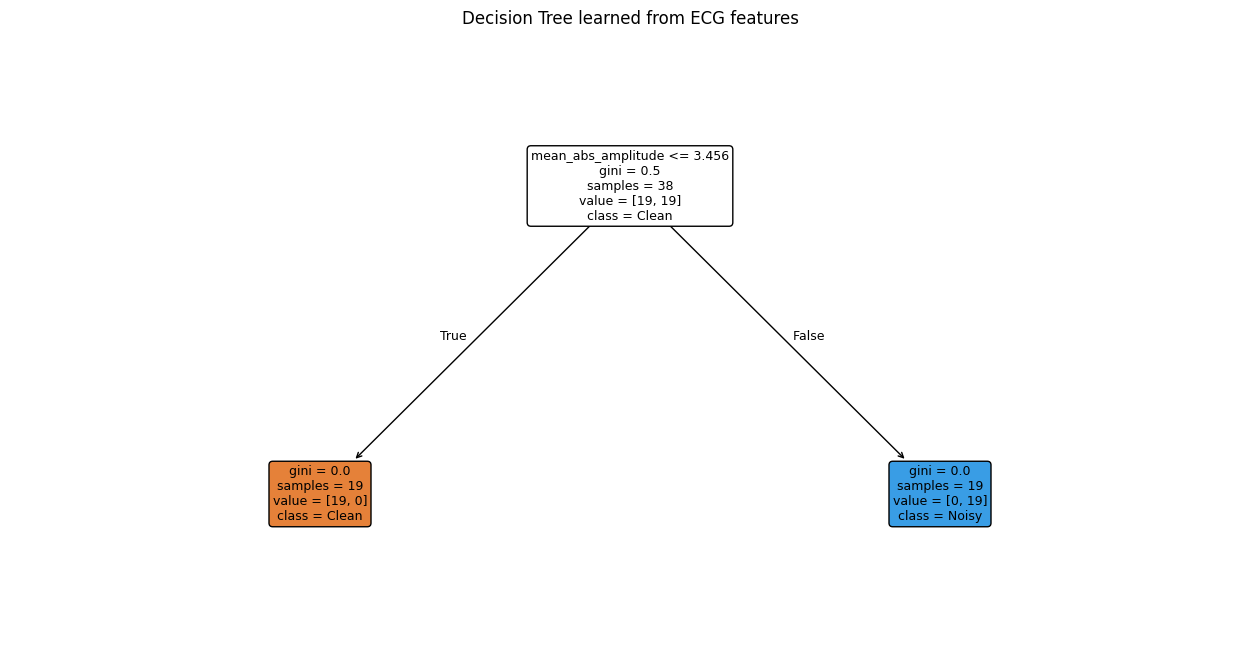

In [17]:
plt.figure(figsize=(16, 8))

plot_tree(tree_model, feature_names=feature_names, class_names=["Clean", "Noisy"], filled=True, rounded=True, fontsize=9)

plt.title("Decision Tree learned from ECG features")
plt.show()

## Tree depth and overfitting

If we let the tree grow without restriction, it can keep creating branches until it explains small details of the training data.

That can lead to **overfitting**:

```text
very good training fit

but poor generalization to new data
```

Common controls include:

- `max_depth`;
- `min_samples_split`;
- `min_samples_leaf`;
- `max_leaf_nodes`.

We will study tuning more deeply in the later ML course.

## Decision Tree feature importance

A fitted tree can report which features contributed most to its splits.

A value of zero means the feature was not used by this fitted tree.

Again:

> feature importance is a property of the fitted model — not proof that the feature is clinically important.

In [13]:
tree_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": tree_model.feature_importances_
})

tree_importance.sort_values("importance", ascending=False)

,feature,importance
4,mean_abs_amplitude,1.0
0,std,0.0
1,amplitude_range,0.0
2,mean_abs_change,0.0
3,derivative_rms,0.0


## Logistic Regression vs Decision Tree

| Logistic Regression | Decision Tree |
|---|---|
| linear decision boundary | nonlinear rule-based boundary |
| naturally gives probabilities | also provides class probabilities |
| usually benefits from scaling | generally does not need scaling |
| coefficients can be inspected | tree rules can be inspected |
| relatively stable/simple | can overfit if grown too deeply |
| combines all features in one equation | may use only a subset of features |

Neither is automatically “better”.

The data and evaluation determine usefulness.

## Same scikit-learn interface

One reason scikit-learn is useful:

```python
model.fit(X_train, y_train)

model.predict(X_test)

model.predict_proba(X_test)
```

The same workflow applies to many models.

This makes fair model comparison easier.

## Exercise 1 — Probabilities with Logistic Regression (30 min)

Use the existing ECG feature table.

### Tasks

1. use only:
   - `std`
   - `derivative_rms`
   - `mean_abs_amplitude`;
2. create a new Logistic Regression pipeline;
3. fit it using the same training rows;
4. calculate class-1 probabilities for the test rows;
5. sort test examples from **lowest to highest probability**;
6. identify:
   - the most confidently clean example;
   - the most confidently noisy example;
   - the example closest to 0.50;
7. write two observations.

### Starter code

In [14]:
exercise_features = ["std", "derivative_rms", "mean_abs_amplitude"]

X_train_ex = X_train[exercise_features]

X_test_ex = X_test[exercise_features]

# TODO:
# Create a StandardScaler + LogisticRegression pipeline.

logistic_ex = None

# TODO:
# Fit the model.

# TODO:
# Obtain class-1 probabilities.

prob_ex = None

# TODO:
# Build a table with:
# true_label
# probability_class_1
# predicted_label

# TODO:
# Sort by probability.

## Exercise 2 — How does tree depth change the model? (30 min)

Train three Decision Trees using the same features:

```text
max_depth = 1
max_depth = 2
max_depth = 4
```

### Tasks

For each tree:

1. fit the model;
2. record training accuracy;
3. record test accuracy;
4. record number of leaves;
5. store the results in a DataFrame;
6. plot depth vs training/test accuracy;
7. inspect one of the trees using `plot_tree()`.

### Question

What changes as the tree becomes deeper?

Do not try to find the “best” depth yet — formal model selection belongs later.

In [15]:
depths = [1, 2, 4]

rows = []

for depth in depths:

    # TODO:
    # Fit DecisionTreeClassifier(max_depth=depth).

    model = None

    # TODO:
    # Calculate training accuracy.

    train_accuracy = None

    # TODO:
    # Calculate test accuracy.

    test_accuracy = None

    # TODO:
    # Obtain number of leaves.

    n_leaves = None

    rows.append({
        "max_depth":
            depth,

        "train_accuracy":
            train_accuracy,

        "test_accuracy":
            test_accuracy,

        "n_leaves":
            n_leaves
    })

depth_results = pd.DataFrame(rows)

depth_results

,max_depth,train_accuracy,test_accuracy,n_leaves
0,1,None,None,None
1,2,None,None,None
2,4,None,None,None


## Project connection

For your semester project, define:

- **target variable:**  
- **classification or regression:**  
- **one row in `X` represents:**  
- **features included:**  
- **features that should NOT be included:**  
- **baseline model:**  
- **grouping variable needed for Lecture 9:**  

### Recommended baseline strategy

Start simple:

```text
interpretable features
        ↓
Logistic Regression
        ↓
Decision Tree
```

Only then move to more complex models.

## Take-home checklist

Before fitting a model, ask:

- What exactly is `X`?
- What exactly is `y`?
- Is each row a participant, record or window?
- Did I accidentally include an identifier as a feature?
- Does the model require scaling?
- Am I using probability or only the final class?
- Can I inspect what the model learned?
- Is my train/test split scientifically valid?
